# Anexo. Teorema del Límite Central con la hora de validación

**Punto de la rúbrica:** b (distribuciones y patrones) y sustento estadístico para el modelo y para los intervalos de confianza del proyecto.

## La pregunta

El profesor propuso verificar el **Teorema del Límite Central (TLC)** con una medida concreta. El TLC dice que, si se toman muestras de tamaño *n* de una población con media μ y desviación σ (finita), **los promedios de las muestras se distribuyen aproximadamente normal con media μ y desviación σ/√n**, aunque la población original no sea normal; la aproximación mejora al crecer *n*.

## ¿Con qué medida y por qué?

> **La medida es el minuto del día en que ocurre una validación** (de 0 a 1.439) y el estadístico es su **promedio muestral** (la "hora media de llegada" de *n* pasajeros).

| Medida candidata | ¿Sirve para ilustrar el TLC? |
|---|---|
| **Minuto del día de la validación** | **Sí.** Es una variable continua con 25,9 millones de observaciones, su distribución es claramente **no normal** (dos picos) y su promedio tiene lectura operativa (a qué hora llega la gente). Si el promedio de muestras sale normal aquí, el teorema se ve funcionando. |
| Valor cobrado ($0 o $3.550) | Solo dos valores; sirve para un promedio = proporción (binomial), poco informativo. |
| Validaciones por estación-hora | Es un conteo agregado, no una observación por pasajero; entre días ya es casi normal. Se usa más abajo para intervalos de confianza. |
| Duración de la jornada (por tarjeta) | Buena (tiene forma de campana, sección 7 del notebook 03), pero exige reconstruir viajes por tarjeta; queda como extensión. |

## ¿Notebook aparte?

**Sí.** Es una verificación estadística independiente del EDA (no cambia las decisiones del análisis) y se puede leer y presentar por separado.

## Qué se hace

1. Describir la población (todas las validaciones de los 14 días hábiles) y comprobar que **no es normal**.
2. Ver **un ejemplo concreto** de muestra con filas reales y **simular** miles de muestras de distintos tamaños *n*, calcular sus promedios y ver cómo se acercan a la normal; comparar la desviación observada con σ/√n.
3. Medir **a qué tamaño de muestra** la aproximación es buena (distancia de Kolmogorov-Smirnov y gráficos cuantil-cuantil).
4. **Aplicarlo**: (a) intervalos de confianza para la hora media de llegada a una estación y su cobertura real; (b) intervalos para el promedio histórico de una estación-hora (la línea base del modelo); (c) **validar con la variable del modelo** (`validaciones`): ¿qué tan seguros podemos estar de la línea base y de los umbrales de presión? (sección 7).

## En palabras simples (leer primero)

**La variable es la hora a la que alguien pasa la tarjeta.** Cada validación trae una marca de tiempo, por ejemplo `06:25:41`. Se convierte a un solo número: los **minutos que han pasado desde la medianoche** (*horas x 60 + minutos*). Ejemplos:

| Hora de la validación | Cuenta | Minuto del día |
|---|---|---|
| 00:00 (medianoche) | 0 x 60 + 0 | 0 |
| 06:25 | 6 x 60 + 25 | 385 |
| 12:09 | 12 x 60 + 9 | 729 |
| 17:10 | 17 x 60 + 10 | 1.030 |
| 23:59 | 23 x 60 + 59 | 1.439 |

Se hace así porque **no se puede promediar "06:25" con "17:10" directamente**, pero sí sus minutos: (385 + 1.030) / 2 = 707,5, que vuelve a ser las **11:47**. Los segundos se ignoran. Hay 25,9 millones de esos números, uno por validación. No es una variable del modelo: es la **variable de prueba** para verificar el teorema, porque el profesor pidió verificar el teorema "con una medida".

**El experimento, en tres pasos:**
1. Se sacan al azar *n* validaciones (por ejemplo 30) y se calcula su **hora promedio** (por ejemplo, las 12:03).
2. Se repite miles de veces. Se obtienen miles de horas promedio, una por muestra.
3. Se dibujan esas horas promedio. **El teorema dice que forman una campana centrada en la hora promedio real (12:09)**, aunque las horas individuales tengan *dos jorobas* (mañana y tarde) y no se parezcan a una campana.

**¿Por qué esta variable y no otra?** Porque es la más clara para ver el teorema: (a) hay una por cada validación (muchísimos datos), (b) **no es normal** (dos picos), así que si los promedios salen normales *se nota* que el teorema funciona, y (c) su promedio tiene sentido práctico ("¿a qué hora llega la gente?"). La variable del modelo, `validaciones` por estación y hora, ya es un conteo agregado: no tiene una observación por pasajero y por eso no sirve para esta demostración (se usa en la sección 6 para otra cosa: el margen de error del promedio de 14 días).

**¿Cómo ayuda esto al análisis? (con honestidad)**
- **Directamente, poco:** esta variable no entra al modelo ni cambia las decisiones del EDA. Es un requisito del curso y una prueba estadística.
- **Indirectamente, sí, de dos maneras:**
  1. *Es la materia prima de la variable objetivo.* Contar cuántas validaciones caen en cada hora es el histograma de esta misma variable; por eso la forma de dos picos que se ve aquí es la que el modelo debe predecir.
  2. *Enseña a medir cuánto confiar en un promedio*, que es lo que usa la línea base del modelo: por ejemplo, "con 100 pasajeros la hora media de llegada se conoce con ±12 minutos" y, en la sección 6, "el promedio de 14 días de una estación-hora tiene un margen de ±3,7 %". Las secciones 6 y 7 son las que sí tocan la variable del modelo: la 7 comprueba, con los datos reales de `validaciones`, qué tan confiable es la línea base y en cuántas estaciones-hora se puede estar seguro de si se supera un umbral de presión.

In [1]:
# QUÉ HACE: carga librerías, rutas y colores, y lee la tabla estación-fecha-hora del notebook 03 para saber cuáles son los 14 días hábiles completos.
# CÓMO: el calendario (tipo de día y día completo) viene de panel_estacion_hora.parquet, guardado en el notebook 03.
# QUÉ MIRAR: 14 días hábiles del 3 de agosto al 18 de septiembre.
import time, warnings
import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
dask.config.set(scheduler='threads', num_workers=3)
VALIDACIONES = Path('../data/processed/validaciones')
PANEL = Path('../data/processed/panel_estacion_hora.parquet')
FIGS = Path('../docs/figs'); FIGS.mkdir(parents=True, exist_ok=True)
COL = {'hábil': '#2a78d6', 'sábado': '#eb6834', 'domingo': '#1baf7a', 'festivo': '#e34948'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'legend.frameon': False})
panel = pd.read_parquet(PANEL)
habiles = sorted(panel.loc[(panel['tipo_dia'] == 'hábil') & panel['completo'], 'fecha'].unique())
print(f"{len(habiles)} días hábiles: {habiles[0]} a {habiles[-1]}")

14 días hábiles: 2026-08-03 a 2026-09-18


## 1. La población: el minuto de cada validación

La **población** son las validaciones de los 14 días hábiles (25,9 millones). Para cada una se toma el minuto del día. Se miran dos poblaciones:

- **A. Día completo:** dos picos (mañana y tarde) con un valle en medio; claramente no normal.
- **B. Ventana de la mañana (4:00 a 9:59):** un solo pico, casi una campana pero con la cima más plana (visto en el notebook 03).

Conteo por minuto en 14 s | validaciones: 25,931,574


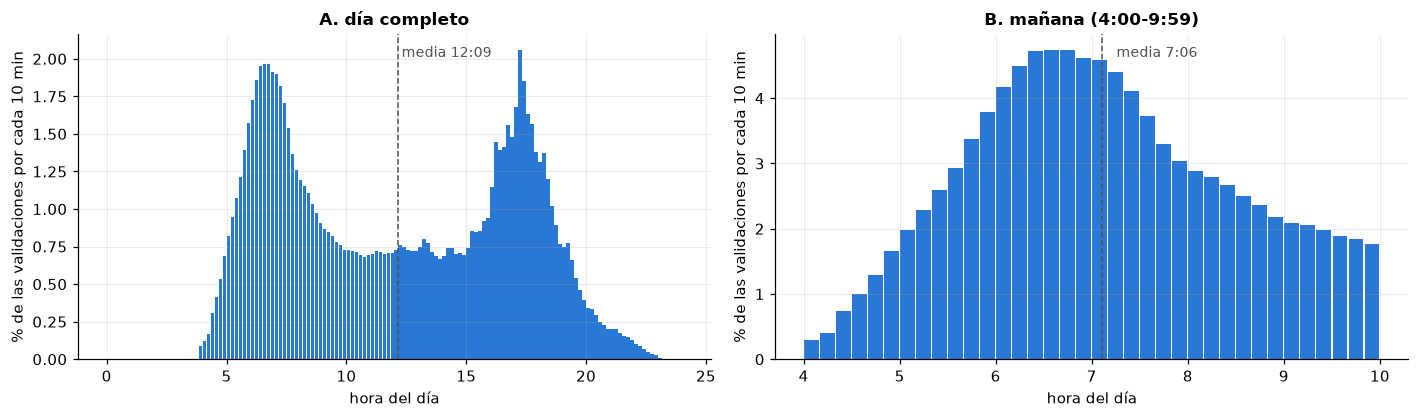

,media (min),desviación σ (min),asimetría,curtosis (exceso),hora media
A. día completo,729.38,292.86,0.10,-1.39,12:09
B. mañana (4:00-9:59),426.46,82.21,0.17,-0.72,7:06


In [2]:
# QUÉ HACE: cuenta las validaciones de los días hábiles minuto a minuto y describe las dos poblaciones (día completo y ventana de la mañana) con sus medidas de forma.
# CÓMO: Dask lee la columna de fecha-hora y cuenta por minuto del día; con esos conteos se calculan media, desviación, asimetría y curtosis en exceso (una normal tiene 0 en las dos últimas); el gráfico muestra la forma en barras de 10 minutos.
# QUÉ MIRAR: la población A tiene dos picos y curtosis negativa fuerte (-1,4): no es normal; la B es casi simétrica pero con la cima plana (-0,7).
t0 = time.perf_counter()
ft = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion'])['Fecha_Transaccion']
minuto = ft.str[11:13].astype('int64') * 60 + ft.str[14:16].astype('int64')
cuentas = (minuto[ft.str[:10].isin(habiles)].to_frame('m').groupby('m').size().compute().reindex(range(1440), fill_value=0))
print(f"Conteo por minuto en {time.perf_counter() - t0:.0f} s | validaciones: {cuentas.sum():,}")

def poblacion(ini, fin):
    m = np.arange(ini, fin); w = cuentas.loc[ini:fin - 1].values.astype(float)
    return m, w / w.sum()
POB = {'A': poblacion(0, 1440), 'B': poblacion(240, 600)}
NOMBRE = {'A': 'A. día completo', 'B': 'B. mañana (4:00-9:59)'}

def momentos(m, p):
    mu = (m * p).sum(); sd = np.sqrt((p * (m - mu) ** 2).sum())
    return {'media (min)': mu, 'desviación σ (min)': sd, 'asimetría': (p * ((m - mu) / sd) ** 3).sum(), 'curtosis (exceso)': (p * ((m - mu) / sd) ** 4).sum() - 3}
hhmm = lambda x: f"{int(x // 60)}:{int(round(x % 60)):02d}"
momentos_pob = pd.DataFrame({NOMBRE[k]: momentos(*POB[k]) for k in POB}).T
momentos_pob['hora media'] = [hhmm(v) for v in momentos_pob['media (min)']]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, k in zip(axes, POB):
    m, p = POB[k]
    barras = pd.Series(p, index=m).groupby(m // 10).sum()
    ax.bar(barras.index * 10 / 60 + 5 / 60, barras.values * 100, width=10 / 60 * 0.92, color=COL['hábil'])
    mu = momentos_pob.loc[NOMBRE[k], 'media (min)'] / 60
    ax.axvline(mu, color='#52514e', lw=1, ls='--'); ax.text(mu + 0.15, ax.get_ylim()[1] * 0.93, f"media {hhmm(mu * 60)}", fontsize=9, color='#52514e')
    ax.set_title(NOMBRE[k]); ax.set_xlabel('hora del día'); ax.set_ylabel('% de las validaciones por cada 10 min')
plt.tight_layout(); plt.savefig(FIGS / 'anexo_poblacion.png', bbox_inches='tight'); plt.show()
momentos_pob.round(2)

## 2. Un ejemplo concreto: de dónde sale una muestra

Una **muestra** es un conjunto de *n* filas de la tabla de validaciones elegidas al azar. Cada fila es una validación real, con su fecha-hora; de cada una se toma su **minuto del día**, y la muestra se resume con **un solo número: el promedio de esos minutos**.

Para verlo con datos reales se toma primero un **subconjunto aleatorio de unas 200.000 validaciones** de los 14 días hábiles (el 0,8 % de la tabla, para que quepa en memoria y se pueda mirar). De ahí se sacan, por ejemplo, **3 muestras de n = 5 validaciones** y se calcula el promedio de cada una. **Cada promedio es un solo punto** del histograma que se construye después: si se repite miles de veces, se obtiene la distribución del promedio.

Subconjunto aleatorio de la tabla: 207,453 validaciones de 25,931,574 (0.80 %) en 6 s
Media real de la población (todas las validaciones): 12:09  |  media de este subconjunto: 12:09

MUESTRA 1 (n = 5 validaciones elegidas al azar):


,fecha y hora de la validación,estación,minuto del día
0,2026-08-06 17:09:04,Temporal AV Jimenez - Inte,1029
1,2026-09-17 12:56:04,Virrey - Cendiatra,776
2,2026-09-15 07:10:37,Cabecera Calle 80,430
3,2026-08-05 10:53:18,Portal Norte - Unicervante,653
4,2026-09-16 08:13:40,Ampliacion San Mateo,493


MUESTRA 2 (n = 5 validaciones elegidas al azar):


,fecha y hora de la validación,estación,minuto del día
0,2026-08-13 15:08:16,Alcalá – Colegio S. Tomás,908
1,2026-09-16 12:02:43,SAN MATEO - C.C. UNISUR,722
2,2026-08-05 06:49:02,Calle 161,409
3,2026-09-16 16:47:50,PALOQUEMAO,1007
4,2026-08-13 04:50:20,Portal 20 de Julio,290


MUESTRA 3 (n = 5 validaciones elegidas al azar):


,fecha y hora de la validación,estación,minuto del día
0,2026-08-14 06:40:05,Cabecera Calle 80,400
1,2026-08-12 17:53:03,El Tiempo - Camara de Come,1073
2,2026-09-15 18:08:45,COMUNEROS,1088
3,2026-08-04 13:50:13,Corral Portal Dorado,830
4,2026-09-17 21:39:18,Calle 127,1299


Resumen: cada muestra se reduce a UN número (su promedio):


,minutos de las 5 validaciones,promedio (min),promedio (hora)
muestra,,,
1,"1029, 776, 430, 653, 493",676.2,11:16
2,"908, 722, 409, 1007, 290",667.2,11:07
3,"400, 1073, 1088, 830, 1299",938.0,15:38


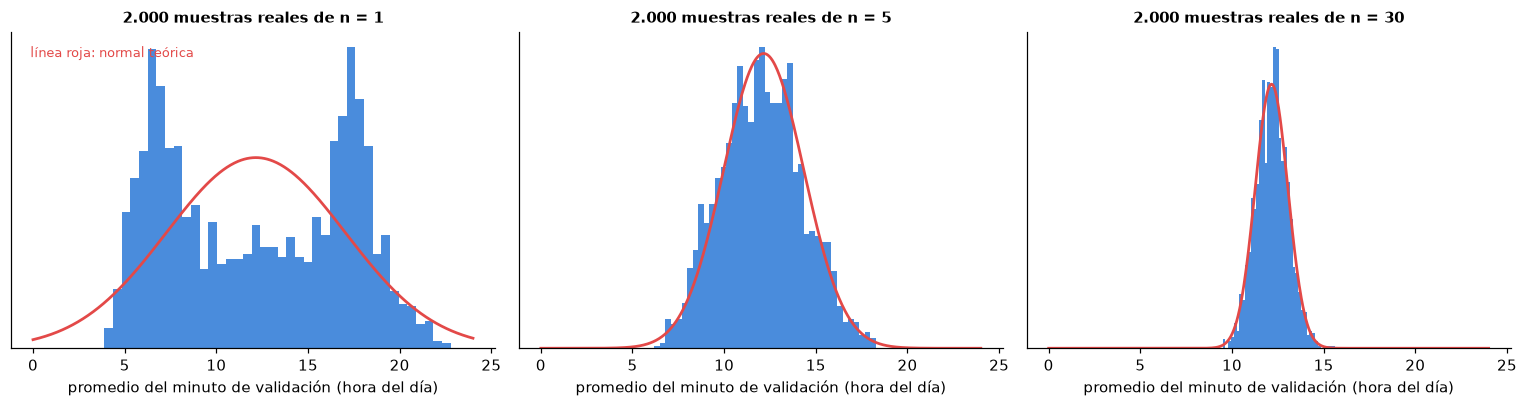

In [3]:
# QUÉ HACE: muestra con filas reales de la tabla qué es una muestra: toma 3 muestras de 5 validaciones, imprime esas filas y calcula el promedio de cada una; luego repite el experimento con datos reales (2.000 muestras de n = 1, 5 y 30) y compara con la normal teórica.
# CÓMO: Dask toma al azar ~0,8 % de las validaciones de los 14 días hábiles (unas 200.000 filas); de ahí, .sample(5) elige 5 filas al azar; el promedio de su columna "minuto" es el estadístico; la normal teórica usa la media y la desviación de la población completa (sección 1).
# QUÉ MIRAR: cada tabla pequeña es UNA muestra (5 filas reales) y su promedio es UN número; los tres promedios son distintos entre sí y distintos de la media real (12:09). En los histogramas, cada barra se construye con 2.000 promedios como esos.
t0 = time.perf_counter()
vm = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion', 'Estacion_Parada'])
vm = vm[vm['Fecha_Transaccion'].str[:10].isin(habiles)]
real = vm.sample(frac=0.008, random_state=11).compute().reset_index(drop=True)
real['estación'] = real['Estacion_Parada'].str[8:].str[:26]
real['minuto'] = real['Fecha_Transaccion'].str[11:13].astype(int) * 60 + real['Fecha_Transaccion'].str[14:16].astype(int)
print(f"Subconjunto aleatorio de la tabla: {len(real):,} validaciones de {cuentas.sum():,} ({len(real) / cuentas.sum() * 100:.2f} %) en {time.perf_counter() - t0:.0f} s")
mom = momentos(*POB['A']); mu0, sd0 = mom['media (min)'], mom['desviación σ (min)']
print(f"Media real de la población (todas las validaciones): {hhmm(mu0)}  |  media de este subconjunto: {hhmm(real['minuto'].mean())}\n")

ejemplos = []
for k in range(3):
    s = real.sample(5, random_state=100 + k)
    print(f"MUESTRA {k + 1} (n = 5 validaciones elegidas al azar):")
    display(s[['Fecha_Transaccion', 'estación', 'minuto']].rename(columns={'Fecha_Transaccion': 'fecha y hora de la validación', 'minuto': 'minuto del día'}).reset_index(drop=True))
    ejemplos.append({'muestra': k + 1, 'minutos de las 5 validaciones': ', '.join(str(v) for v in s['minuto']), 'promedio (min)': round(s['minuto'].mean(), 1), 'promedio (hora)': hhmm(s['minuto'].mean())})
print('Resumen: cada muestra se reduce a UN número (su promedio):')
display(pd.DataFrame(ejemplos).set_index('muestra'))

rng_r = np.random.default_rng(5)
x_real = real['minuto'].values
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, n in zip(axes, [1, 5, 30]):
    prom = x_real[rng_r.integers(0, len(x_real), size=(2000, n))].mean(axis=1)           # 2.000 muestras de n filas reales
    xs = np.linspace(0, 1440, 600)
    ax.hist(prom / 60, bins=40, density=True, color=COL['hábil'], alpha=0.85)
    ax.plot(xs / 60, stats.norm.pdf(xs, mu0, sd0 / np.sqrt(n)) * 60, color='#e34948', lw=1.8)
    ax.set_title(f"2.000 muestras reales de n = {n}", fontsize=10); ax.set_xlabel('promedio del minuto de validación (hora del día)'); ax.set_yticks([]); ax.grid(False)
axes[0].text(0.04, 0.92, 'línea roja: normal teórica', transform=axes[0].transAxes, fontsize=8.5, color='#e34948')
plt.tight_layout(); plt.savefig(FIGS / 'anexo_ejemplo_muestras_reales.png', bbox_inches='tight'); plt.show()

## 3. Simular: promedios de muestras de tamaño *n*

Se repite 5.000 veces: *se extraen n validaciones al azar (con la distribución real de la población), se calcula su minuto promedio*. Con *n* = 1 el "promedio" es la propia población; al crecer *n* debería aparecer una campana centrada en μ con ancho σ/√n. La línea roja es esa normal teórica.

**Cómo se sacan las muestras:** igual que en el ejemplo anterior (n filas al azar de la tabla de validaciones), pero en lugar de usar las 25,9 millones de filas se usa la **tabla de conteos por minuto** (cuántas validaciones hubo en cada minuto del día): elegir un minuto con probabilidad proporcional a su conteo es lo mismo que elegir una fila al azar, y es mucho más rápido. La extracción con reposición es prácticamente equivalente a la de sin reposición porque la muestra es diminuta frente a la población.

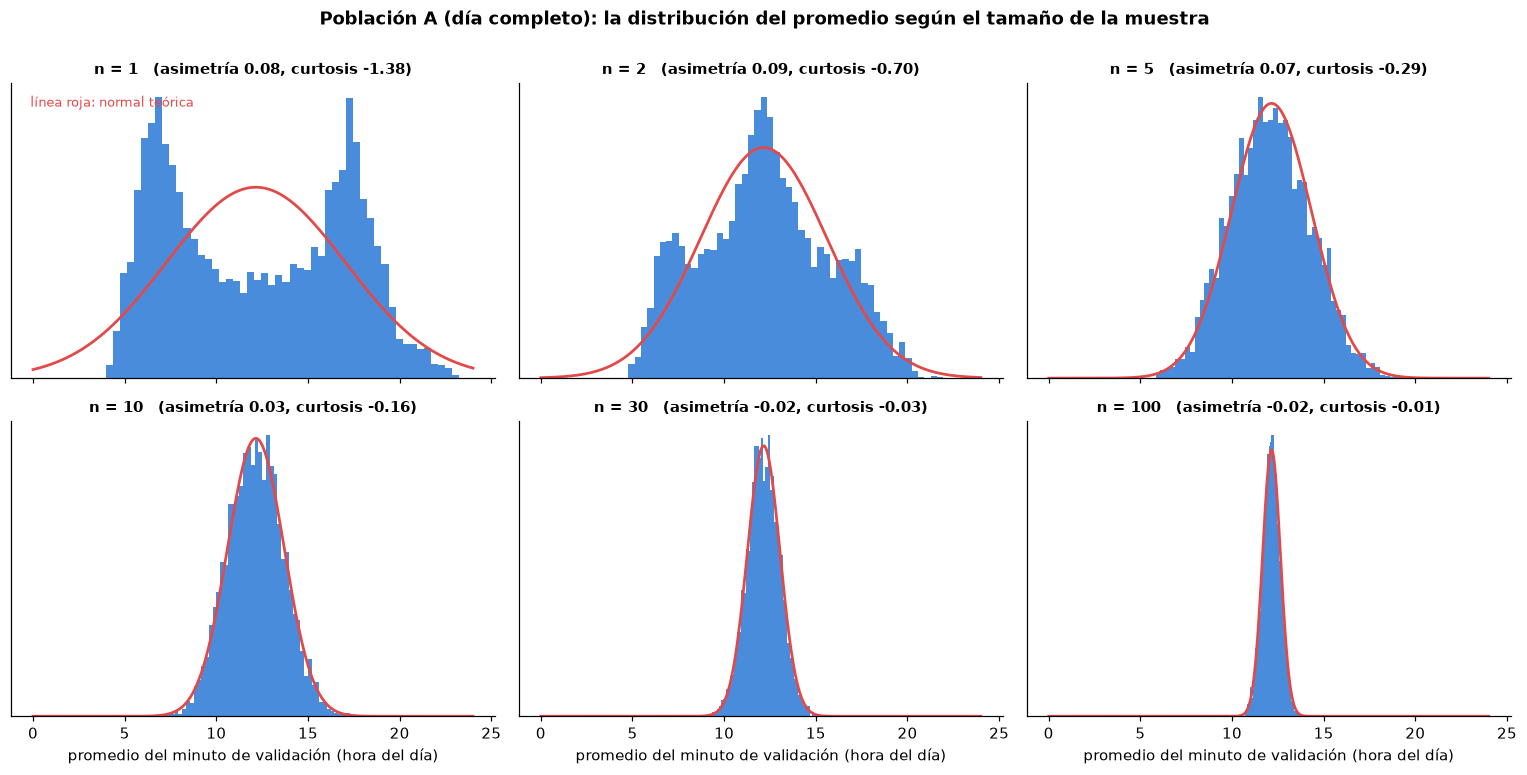

In [4]:
# QUÉ HACE: simula 5.000 muestras para cada tamaño n (1, 2, 5, 10, 30, 100), calcula el promedio de cada una y dibuja los histogramas con la normal teórica N(μ, σ/√n) encima.
# CÓMO: las muestras se sacan al azar con las probabilidades reales de cada minuto del día; en el título de cada panel van la asimetría y la curtosis de los promedios (0 y 0 en una normal).
# QUÉ MIRAR: con n = 1 se ve la población (dos picos); con n = 2 todavía se notan dos jorobas; desde n = 5 la campana ya sigue la línea roja; con n = 30 y n = 100 es casi perfecta y mucho más angosta.
rng = np.random.default_rng(2026)
R = 5000
def promedios(k, n, R=R):
    m, p = POB[k]
    return m[rng.choice(len(m), size=(R, n), p=p)].mean(axis=1)

NS = [1, 2, 5, 10, 30, 100]
medias_A = {n: promedios('A', n) for n in NS}
mom_A = momentos(*POB['A']); mu_A, sd_A = mom_A['media (min)'], mom_A['desviación σ (min)']

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
xs = np.linspace(0, 1440, 600)
for ax, n in zip(axes.ravel(), NS):
    x = medias_A[n]
    ax.hist(x / 60, bins=50, density=True, color=COL['hábil'], alpha=0.85)
    ax.plot(xs / 60, stats.norm.pdf(xs, mu_A, sd_A / np.sqrt(n)) * 60, color='#e34948', lw=1.8)
    ax.set_title(f"n = {n}   (asimetría {stats.skew(x):.2f}, curtosis {stats.kurtosis(x):.2f})", fontsize=10)
    ax.set_yticks([]); ax.grid(False)
for ax in axes[1]: ax.set_xlabel('promedio del minuto de validación (hora del día)')
axes[0, 0].text(0.04, 0.92, 'línea roja: normal teórica', transform=axes[0, 0].transAxes, fontsize=8.5, color='#e34948')
fig.suptitle('Población A (día completo): la distribución del promedio según el tamaño de la muestra', fontweight='bold', y=1.0)
plt.tight_layout(); plt.savefig(FIGS / 'anexo_promedios_poblacion_A.png', bbox_inches='tight'); plt.show()

## 4. ¿A partir de qué tamaño funciona? σ/√n y distancia a la normal

Dos comprobaciones numéricas para las dos poblaciones:

1. **σ/√n:** la desviación de los promedios simulados debe coincidir con la teórica.
2. **Distancia de Kolmogorov-Smirnov (KS)** entre los promedios simulados y la normal teórica N(μ, σ/√n): es la mayor diferencia entre las dos curvas acumuladas (0 = idénticas). Con 5.000 simulaciones, el "ruido" del azar para una normal perfecta es ~0,02; por debajo de eso no se distingue de una normal.

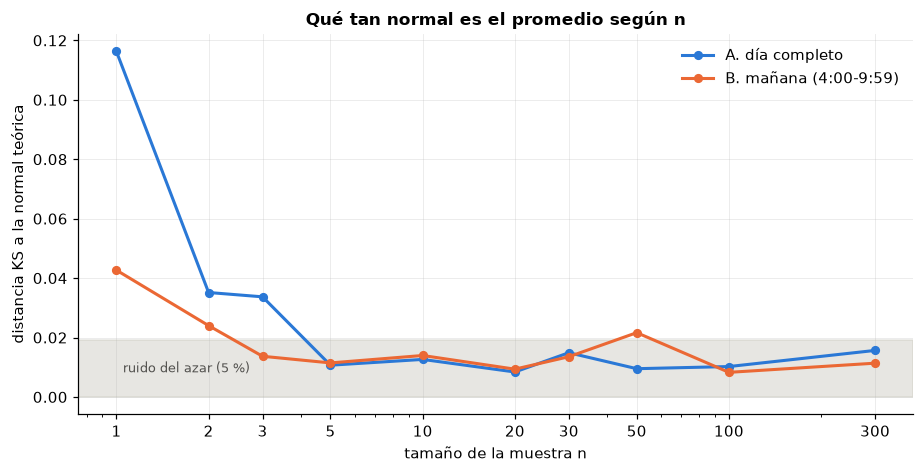

Primer n con distancia KS < 0,03: {'A. día completo': 5, 'B. mañana (4:00-9:59)': 2}


σ/√n teórica (min)  desv. simulada (min)  asimetría  curtosis (exceso)  distancia KS
población             n                                                                                        
A. día completo       1               292.864               290.119      0.119             -1.380         0.116
                      2               207.086               206.505      0.052             -0.707         0.035
                      3               169.085               170.302      0.027             -0.524         0.034
                      5               130.973               129.195      0.098             -0.295         0.011
                      10               92.612                93.031      0.024             -0.190         0.013
                      20               65.486                65.982     -0.031              0.019         0.008
                      30               53.469                52.626      0.047              0.165         0.015
                      50               41.417                41.357     -0.002             -0.050         0.010
                      100              29.286                28.665     -0.015             -0.089         0.010
                      300              16.908                16.886      0.042             -0.046         0.016
B. mañana (4:00-9:59) 1                82.206                82.343      0.183             -0.729         0.043
                      2                58.128                58.420      0.121             -0.321         0.024
                      3                47.461                47.573      0.106             -0.232         0.014
                      5                36.763                36.741      0.073             -0.131         0.011
                      10               25.996                26.271      0.047             -0.080         0.014
                      20               18.382                18.125      0.008              0.012         0.009
                      30               15.009                15.244      0.025             -0.041         0.014
                      50               11.626                11.603      0.019              0.008         0.022
                      100               8.221                 8.311     -0.009             -0.040         0.008
                      300               4.746                 4.708      0.056             -0.091         0.011

In [5]:
# QUÉ HACE: compara la desviación simulada con σ/√n y mide la distancia KS a la normal para cada tamaño de muestra, en las dos poblaciones.
# CÓMO: para cada n (1 a 300) se simulan 5.000 promedios; la tabla muestra desviación teórica y simulada, asimetría, curtosis y distancia KS; el gráfico dibuja la distancia KS contra n (eje horizontal logarítmico) con la banda de ruido del azar (1,36/√5.000 ≈ 0,019).
# QUÉ MIRAR: la desviación simulada coincide con σ/√n en todos los n; la distancia KS entra en la banda de ruido desde n = 5 (población A) y n = 3 (población B), antes de lo que sugiere la regla práctica de n >= 30; las pequeñas subidas posteriores dentro de la banda son azar de la simulación.
NS2 = [1, 2, 3, 5, 10, 20, 30, 50, 100, 300]
filas = []
for k in POB:
    mom = momentos(*POB[k]); mu, sd = mom['media (min)'], mom['desviación σ (min)']
    for n in NS2:
        x = promedios(k, n)
        filas.append({'población': NOMBRE[k], 'n': n, 'σ/√n teórica (min)': sd / np.sqrt(n), 'desv. simulada (min)': x.std(ddof=1),
                      'asimetría': stats.skew(x), 'curtosis (exceso)': stats.kurtosis(x), 'distancia KS': stats.kstest((x - mu) / (sd / np.sqrt(n)), 'norm').statistic})
tabla_ks = pd.DataFrame(filas)
ruido = 1.36 / np.sqrt(R)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for k, c in [('A. día completo', COL['hábil']), ('B. mañana (4:00-9:59)', '#eb6834')]:
    d = tabla_ks[tabla_ks['población'] == k]
    ax.plot(d['n'], d['distancia KS'], marker='o', ms=5, lw=2, color=c, label=k)
ax.axhspan(0, ruido, color='#c3c2b7', alpha=0.4); ax.text(1.05, ruido / 2, 'ruido del azar (5 %)', fontsize=8.5, va='center', color='#52514e')
ax.set_xscale('log'); ax.set_xticks(NS2); ax.set_xticklabels(NS2)
ax.set_xlabel('tamaño de la muestra n'); ax.set_ylabel('distancia KS a la normal teórica'); ax.set_title('Qué tan normal es el promedio según n')
ax.legend()
plt.tight_layout(); plt.savefig(FIGS / 'anexo_distancia_ks.png', bbox_inches='tight'); plt.show()
primero = {k: int(tabla_ks[(tabla_ks['población'] == k) & (tabla_ks['distancia KS'] < 0.03)]['n'].min()) for k in NOMBRE.values()}
print('Primer n con distancia KS < 0,03:', primero)
tabla_ks.set_index(['población', 'n']).round(3)

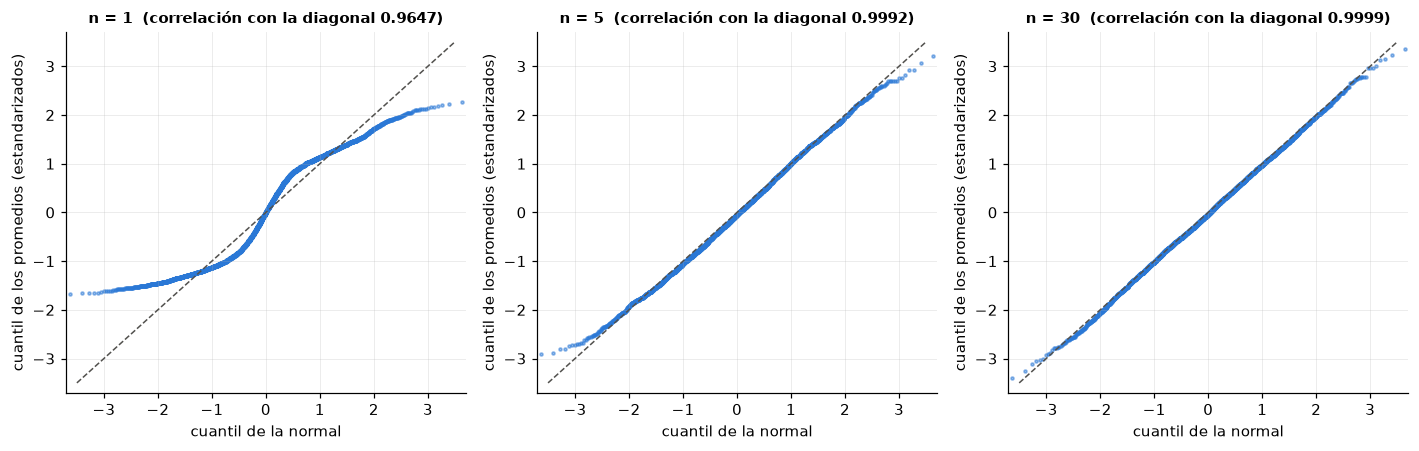

In [6]:
# QUÉ HACE: dibuja el gráfico cuantil-cuantil (Q-Q) de los promedios de la población A para n = 1, 5 y 30.
# CÓMO: cada punto compara un cuantil de los promedios simulados (estandarizados) con el cuantil de una normal; si los puntos siguen la diagonal, es normal.
# QUÉ MIRAR: con n = 1 la curva es una "S" (dos picos); con n = 5 se endereza; con n = 30 los puntos quedan sobre la diagonal, incluso en las colas.
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, n in zip(axes, [1, 5, 30]):
    x = (medias_A[n] - mu_A) / (sd_A / np.sqrt(n))
    (osm, osr), (pend, inter, r) = stats.probplot(x, dist='norm')
    ax.scatter(osm, osr, s=4, color=COL['hábil'], alpha=0.5); ax.plot([-3.5, 3.5], [-3.5, 3.5], color='#52514e', lw=1, ls='--')
    ax.set_title(f"n = {n}  (correlación con la diagonal {r:.4f})", fontsize=10); ax.set_xlabel('cuantil de la normal'); ax.set_ylabel('cuantil de los promedios (estandarizados)')
    ax.set_xlim(-3.7, 3.7); ax.set_ylim(-3.7, 3.7)
plt.tight_layout(); plt.savefig(FIGS / 'anexo_qq_promedios.png', bbox_inches='tight'); plt.show()

## 5. Aplicación (a): intervalo de confianza de la hora media de llegada

Si el promedio es aproximadamente normal, se puede construir un **intervalo de confianza del 95 %** para la media poblacional: x̄ ± t · s/√n. Si el TLC funciona, el intervalo debe **contener la media verdadera en ~95 % de las muestras** (la "cobertura").

Población: las validaciones de la **punta de la mañana (5:00 a 8:59) en una estación grande (Portal Américas)** en los 14 días hábiles. Se conoce su media real (toda la población), así que se puede comprobar la cobertura de verdad.

In [7]:
# QUÉ HACE: para la punta de la mañana en Portal Américas, simula muestras de n pasajeros, construye el intervalo de confianza del 95 % de la hora media de llegada y mide con qué frecuencia contiene la media verdadera.
# CÓMO: Dask trae los minutos de esa estación (código 05000) entre las 5:00 y las 8:59 de los 14 días; se sacan 5.000 muestras por cada n y se calcula x̄ ± t(0,975; n-1) · s/√n; la cobertura es el % de intervalos que contienen la media real.
# QUÉ MIRAR: la cobertura queda cerca de 95 % (93,7 % con n = 5 y 94,6 % con n = 100); el ancho del intervalo baja como 1/√n (con n = 30 la hora media se conoce con ± 23 minutos y con n = 100, con ± 12).
vs = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion', 'Estacion_Parada'])
vs = vs[(vs['Estacion_Parada'].str[1:6] == '05000') & vs['Fecha_Transaccion'].str[:10].isin(habiles)]
m_est = (vs['Fecha_Transaccion'].str[11:13].astype('int64') * 60 + vs['Fecha_Transaccion'].str[14:16].astype('int64'))
cnt_est = m_est.to_frame('m').groupby('m').size().compute().reindex(range(300, 540), fill_value=0)
m_pop = np.arange(300, 540); p_pop = cnt_est.values / cnt_est.sum()
mu_e = (m_pop * p_pop).sum(); sd_e = np.sqrt((p_pop * (m_pop - mu_e) ** 2).sum())
print(f"Población: {cnt_est.sum():,} validaciones en la punta de la mañana de Portal Américas | hora media real {hhmm(mu_e)} | σ = {sd_e:.0f} min")

filas = []
for n in [5, 10, 30, 100]:
    X = m_pop[rng.choice(len(m_pop), size=(R, n), p=p_pop)]
    xb = X.mean(axis=1); s = X.std(axis=1, ddof=1); semi = stats.t.ppf(0.975, n - 1) * s / np.sqrt(n)
    filas.append({'n (pasajeros en la muestra)': n, 'cobertura real del IC 95 % (%)': np.mean(np.abs(xb - mu_e) <= semi) * 100,
                  'semiancho promedio (min)': semi.mean(), 'semiancho teórico 1,96·σ/√n (min)': 1.96 * sd_e / np.sqrt(n)})
pd.DataFrame(filas).set_index('n (pasajeros en la muestra)').round(1)

Población: 587,668 validaciones en la punta de la mañana de Portal Américas | hora media real 6:40 | σ = 62 min


,cobertura real del IC 95 % (%),semiancho promedio (min),"semiancho teórico 1,96·σ/√n (min)"
n (pasajeros en la muestra),,,
5,93.7,73.3,54.2
10,94.2,43.4,38.3
30,94.4,22.9,22.1
100,94.6,12.2,12.1


## 6. Aplicación (b): precisión del promedio histórico de una estación-hora

La **línea base** del modelo es el promedio de los días anteriores de cada estación-hora. Ese promedio es el estadístico del TLC aplicado a **n = 14 días**: con σ desconocida y n pequeño se usa la distribución *t*. Interesa saber **qué tan preciso es** (semiancho del intervalo respecto al promedio) y si las series diarias son razonablemente normales.

Se excluyen las 5 estaciones que abren o cierran entre agosto y septiembre (notebook 03, sección 8), porque su promedio mezcla dos regímenes.

In [8]:
# QUÉ HACE: para cada estación-hora con al menos 1.000 validaciones promedio (5:00-22:59), calcula el promedio de los 14 días, su intervalo de confianza del 95 % con la distribución t y una prueba de normalidad de los 14 valores.
# CÓMO: semiancho = t(0,975; 13) · s/√14, expresado en % del promedio; Shapiro-Wilk sobre los 14 días de cada serie (con n tan pequeño la prueba detecta poco, por eso se muestra junto al coeficiente de variación).
# QUÉ MIRAR: el promedio de 14 días queda con un semiancho de ± 2-4 % en las estaciones-hora más grandes (mediana ± 3,7 % en todas las de 1.000 o más); la mayoría de las series (82 %) no rechaza normalidad, así que usar el promedio y la distribución t es razonable.
ph = panel[(panel['tipo_dia'] == 'hábil') & panel['completo'] & panel['hora'].between(5, 22)]
cu = ph.pivot_table(index=['cod_estacion', 'hora'], columns='fecha', values='validaciones', aggfunc='sum', fill_value=0)
cu = cu.reindex(pd.MultiIndex.from_product([sorted(ph['cod_estacion'].unique()), range(5, 23)], names=['cod_estacion', 'hora']), fill_value=0)
ago = [c for c in cu.columns if c < '2026-09-01']; sep = [c for c in cu.columns if c >= '2026-09-01']
tot = cu.groupby('cod_estacion').sum()
razon = tot[sep].mean(axis=1) / tot[ago].mean(axis=1).replace(0, np.nan)
cambian = tot.index[(tot[ago].sum(axis=1) == 0) | (tot[sep].sum(axis=1) == 0) | (razon < 0.6) | (razon > 1.67)]
print(f"Estaciones que cambian de régimen y se excluyen: {list(cambian)}")
cu = cu[~cu.index.get_level_values('cod_estacion').isin(cambian)]
cu = cu[cu.mean(axis=1) >= 1000]

media = cu.mean(axis=1); desv = cu.std(axis=1, ddof=1); n_d = cu.shape[1]
semiancho = stats.t.ppf(0.975, n_d - 1) * desv / np.sqrt(n_d)
sh = cu.apply(lambda r: stats.shapiro(r.values).pvalue, axis=1)
res = pd.DataFrame({'promedio 14 días': media, 'desviación': desv, 'coef. de variación (%)': desv / media * 100,
                    'semiancho IC 95 % (% del promedio)': semiancho / media * 100, 'p Shapiro-Wilk': sh})
print(f"{len(res)} estaciones-hora con promedio >= 1.000 | mediana del coef. de variación {res['coef. de variación (%)'].median():.1f} % | "
      f"mediana del semiancho del IC {res['semiancho IC 95 % (% del promedio)'].median():.1f} % | "
      f"series que NO rechazan normalidad (p > 0,05): {(sh > 0.05).mean() * 100:.0f} %")

nom = (dd.read_parquet(str(VALIDACIONES), columns=['Estacion_Parada'])['Estacion_Parada'].value_counts().compute().reset_index())
nom.columns = ['crudo', 'n']; nom['cod_estacion'] = nom['crudo'].str[1:6]; nom['nombre'] = nom['crudo'].str[8:]
nom = nom.sort_values('n', ascending=False).drop_duplicates('cod_estacion').set_index('cod_estacion')['nombre']
top = res.sort_values('promedio 14 días', ascending=False).head(10).reset_index()
top['estación'] = top['cod_estacion'].map(nom).str[:28]
top[['estación', 'hora', 'promedio 14 días', 'desviación', 'coef. de variación (%)', 'semiancho IC 95 % (% del promedio)', 'p Shapiro-Wilk']].round(2)

Estaciones que cambian de régimen y se excluyen: ['08100', '09122', '09123', '15001', '15002', '15003', '50004', '50006']


444 estaciones-hora con promedio >= 1.000 | mediana del coef. de variación 6.4 % | mediana del semiancho del IC 3.7 % | series que NO rechazan normalidad (p > 0,05): 82 %


,estación,hora,promedio 14 días,desviación,coef. de variación (%),semiancho IC 95 % (% del promedio),p Shapiro-Wilk
0,Portal Américas,6,14411.64,660.05,4.58,2.64,0.31
1,Portal Américas,5,12654.93,356.96,2.82,1.63,0.60
2,Portal Sur JFK Coop. Financi,6,11663.71,783.88,6.72,3.88,0.04
3,Portal Suba,6,11407.07,326.35,2.86,1.65,0.94
4,Cabecera Usme,6,10449.14,442.34,4.23,2.44,0.09
5,Portal Suba,7,9875.64,374.15,3.79,2.19,0.11
6,Portal Sur JFK Coop. Financi,5,9394.86,364.43,3.88,2.24,0.62
7,Portal Norte - Unicervantes,7,9369.21,503.62,5.38,3.10,0.57
8,Portal Norte - Unicervantes,6,9286.93,325.22,3.50,2.02,0.00
9,Portal Américas,7,9133.57,730.52,8.00,4.62,0.10


## 7. Validar con la variable del modelo: ¿qué tan seguros podemos estar de la línea base?

Sí se puede usar el teorema con una variable que **sí ayuda al análisis**: `validaciones` por estación y hora, que es la variable del modelo. La diferencia con las secciones anteriores es que aquí cada "muestra" es el **conjunto de días ya observados** de una estación-hora (por ejemplo, los 10 primeros días hábiles) y su promedio es la **línea base** (la predicción más simple). Se responden dos preguntas prácticas:

1. **¿El intervalo del 95 % que sale del promedio y la desviación de los días pasados contiene de verdad al día siguiente el 95 % de las veces?** Se hace un *backtest*: con los primeros *k* días se arma el intervalo de predicción (promedio ± t · s · √(1 + 1/k)) y se mira si el día *k + 1* cae dentro. Si la cobertura es ~95 %, el supuesto "los días se comportan como una normal alrededor del promedio" es razonable; si es menor, los intervalos son demasiado optimistas.
2. **¿En cuántas estaciones-hora estamos seguros de si superan un umbral?** Con los 14 días se calcula el intervalo del promedio; si todo el intervalo queda por encima del umbral, **es seguro** que lo supera; si cae por debajo, **es seguro** que no; si el intervalo contiene al umbral, es un caso **dudoso** que conviene revisar con la operación.

*Nota:* se eligen las estaciones-hora con promedio de 14 días >= 1.000, lo que usa información de todos los días; es una verificación del supuesto, no una evaluación del modelo.

In [9]:
# QUÉ HACE: (1) backtest de cobertura: con los primeros k días de cada estación-hora arma un intervalo de predicción del 95 % y mira si el día k+1 cae dentro; (2) cuenta cuántas estaciones-hora están seguras por encima o por debajo de un umbral y cuántas son dudosas.
# CÓMO: (1) intervalo = promedio ± t(0,975; k-1) · s · √(1 + 1/k) para estaciones-hora con promedio >= 1.000 (sin las 5 que cambian de régimen); (2) intervalo del promedio de los 14 días (± t · s/√14) contra el umbral de 500, 1.000 y 2.000 validaciones por hora, en las estaciones-hora con promedio >= 100.
# QUÉ MIRAR: la cobertura del backtest (cerca de 95 % = el supuesto funciona; los lunes deberían salir peor por su efecto de -6 %); qué parte de las estaciones-hora que parecen superar el umbral son seguras y cuántas son dudosas.
DIAS_ES = {0: 'lunes', 1: 'martes', 2: 'miércoles', 3: 'jueves', 4: 'viernes'}
cu_all = ph.pivot_table(index=['cod_estacion', 'hora'], columns='fecha', values='validaciones', aggfunc='sum', fill_value=0)
cu_all = cu_all.reindex(pd.MultiIndex.from_product([sorted(ph['cod_estacion'].unique()), range(5, 23)], names=['cod_estacion', 'hora']), fill_value=0)
cu_all = cu_all[~cu_all.index.get_level_values('cod_estacion').isin(cambian)]
fechas = list(cu_all.columns)
G = cu_all[cu_all.mean(axis=1) >= 1000].values.astype(float)

filas = []
for k in range(4, len(fechas)):
    m = G[:, :k].mean(axis=1); s = G[:, :k].std(axis=1, ddof=1)
    semi = stats.t.ppf(0.975, k - 1) * s * np.sqrt(1 + 1 / k)
    y = G[:, k]
    filas.append({'días usados (k)': k, 'día que se predice': fechas[k], 'día de la semana': DIAS_ES[pd.Timestamp(fechas[k]).dayofweek],
                  'cobertura del intervalo 95 % (%)': np.mean(np.abs(y - m) <= semi) * 100, 'error relativo mediano (%)': np.median(np.abs(y - m) / m) * 100})
bt = pd.DataFrame(filas).set_index('días usados (k)')
print(f"Backtest con {len(G)} estaciones-hora (promedio >= 1.000, sin las que cambian de régimen):")
display(bt.round(1))
por_dia = bt.groupby('día de la semana')[['cobertura del intervalo 95 % (%)', 'error relativo mediano (%)']].mean().reindex(['lunes', 'martes', 'miércoles', 'jueves', 'viernes']).dropna()
print(f"Cobertura promedio de todos los días predichos: {bt['cobertura del intervalo 95 % (%)'].mean():.1f} %. Por día de la semana del día que se predice:")
display(por_dia.round(1))

m14 = cu_all.mean(axis=1); s14 = cu_all.std(axis=1, ddof=1)
lo = m14 - stats.t.ppf(0.975, 13) * s14 / np.sqrt(14); hi = m14 + stats.t.ppf(0.975, 13) * s14 / np.sqrt(14)
rel = m14 >= 100
filas = []
for u in [500, 1000, 2000]:
    seguro_si = int((rel & (lo >= u)).sum()); seguro_no = int((rel & (hi < u)).sum()); dudoso = int((rel & (lo < u) & (hi >= u)).sum())
    filas.append({'umbral (validaciones por hora)': u, 'seguro: lo supera': seguro_si, 'dudoso': dudoso, 'seguro: no lo supera': seguro_no,
                  '% seguros entre los que lo superan o son dudosos': seguro_si / (seguro_si + dudoso) * 100})
certeza = pd.DataFrame(filas).set_index('umbral (validaciones por hora)')
print('Certeza sobre si una estación-hora supera el umbral, con el intervalo del promedio de 14 días:')
certeza.round(1)

Backtest con 444 estaciones-hora (promedio >= 1.000, sin las que cambian de régimen):


,día que se predice,día de la semana,cobertura del intervalo 95 % (%),error relativo mediano (%)
días usados (k),,,,
4,2026-08-10,lunes,88.1,7.3
5,2026-08-11,martes,97.5,3.3
6,2026-08-12,miércoles,97.3,3.7
7,2026-08-13,jueves,95.9,3.6
8,2026-08-14,viernes,89.2,6.0
9,2026-09-14,lunes,86.9,5.2
10,2026-09-15,martes,89.2,5.8
11,2026-09-16,miércoles,93.5,5.2
12,2026-09-17,jueves,98.0,4.4


Cobertura promedio de todos los días predichos: 92.6 %. Por día de la semana del día que se predice:


,cobertura del intervalo 95 % (%),error relativo mediano (%)
día de la semana,,
lunes,87.5,6.2
martes,93.4,4.6
miércoles,95.4,4.5
jueves,97.0,4.0
viernes,89.8,6.0


Certeza sobre si una estación-hora supera el umbral, con el intervalo del promedio de 14 días:


,seguro: lo supera,dudoso,seguro: no lo supera,% seguros entre los que lo superan o son dudosos
umbral (validaciones por hora),,,,
500,870,98,1181,89.9
1000,417,65,1667,86.5
2000,165,30,1954,84.6


## 8. Variante: ¿en qué momento *de cada hora* llega la gente?

Otra variable posible, propuesta durante la revisión: en lugar del minuto del día (0 a 1.439), el **minuto dentro de la hora (0 a 59)**. Por ejemplo, una validación a las 06:25 tiene minuto 25 dentro de la hora 6. La pregunta: **¿dentro de cada hora la gente llega pareja o se concentra al principio o al final?** Esto importa para la operación, porque los datos se agrupan por hora y un pico dentro de la hora queda escondido.

Si la llegada fuera pareja, el minuto dentro de la hora sería **uniforme** (cualquier minuto igual de probable): promedio 29,5 y desviación 17,3. Cualquier diferencia indica que dentro de esa hora la demanda **sube o baja**.

Además, la variable uniforme es la población clásica para ver el Teorema del Límite Central: es plana, nada parecida a una campana, y aun así el promedio de varias muestras sí lo es.

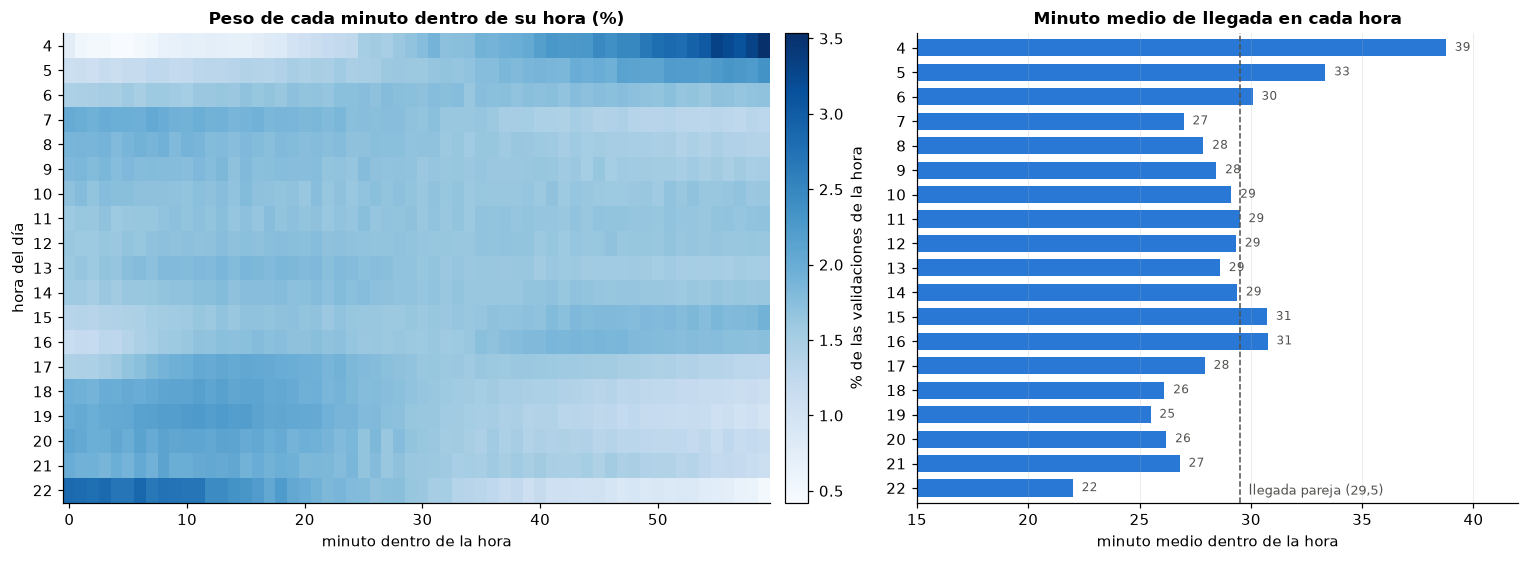

,validaciones,minuto medio,desviación (min),asimetría,% minutos 0-19,% minutos 20-39,% minutos 40-59
hora,,,,,,,
4,579193,38.8,15.2,-0.7,12.9,32.4,54.7
5,1820695,33.3,17.0,-0.3,25.2,32.6,42.2
6,2949683,30.1,17.1,-0.0,31.5,34.4,34.1
7,2487301,27.0,17.0,0.2,38.8,33.8,27.4
8,1651711,27.9,17.2,0.1,36.8,33.6,29.5
9,1246131,28.4,17.3,0.1,35.7,33.3,31.0
10,1098450,29.1,17.4,0.0,34.3,33.2,32.5
11,1100152,29.5,17.3,0.0,33.4,33.4,33.2
12,1140118,29.3,17.2,0.0,33.7,33.6,32.7


In [10]:
# QUÉ HACE: para cada hora del día calcula en qué momento de la hora ocurren las validaciones (minuto dentro de la hora, 0 a 59): minuto medio, desviación y qué porcentaje cae en los primeros 20, los 20 del medio y los últimos 20 minutos.
# CÓMO: usa la tabla de conteos por minuto del día (sección 1) reordenada en 24 filas (horas) x 60 columnas (minutos); el heatmap muestra cuánto pesa cada minuto dentro de su hora y las barras, el minuto medio de cada hora (la línea punteada es 29,5, lo esperado si la llegada fuera pareja).
# QUÉ MIRAR: en las horas de subida (4 y 5) la gente llega más al final de la hora (minuto medio 39 y 33); en las de bajada (7, 18, 19, 22) más al principio (minuto medio entre 22 y 27); en las horas estables (9 a 14) la llegada es pareja (minuto medio ~29).
MH = cuentas.values.reshape(24, 60).astype(float)
mm = np.arange(60)
filas = []
for h in range(4, 23):
    w = MH[h]; p = w / w.sum(); mu = (mm * p).sum(); sd = np.sqrt((p * (mm - mu) ** 2).sum())
    filas.append({'hora': h, 'validaciones': int(w.sum()), 'minuto medio': mu, 'desviación (min)': sd, 'asimetría': (p * ((mm - mu) / sd) ** 3).sum(),
                  '% minutos 0-19': w[:20].sum() / w.sum() * 100, '% minutos 20-39': w[20:40].sum() / w.sum() * 100, '% minutos 40-59': w[40:].sum() / w.sum() * 100})
dentro = pd.DataFrame(filas).set_index('hora')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1.25, 1]})
share = MH[4:23] / MH[4:23].sum(axis=1, keepdims=True) * 100
im = a1.imshow(share, aspect='auto', cmap='Blues', extent=[-0.5, 59.5, 22.5, 3.5])
a1.set_xlabel('minuto dentro de la hora'); a1.set_ylabel('hora del día'); a1.set_yticks(range(4, 23)); a1.grid(False)
a1.set_title('Peso de cada minuto dentro de su hora (%)'); fig.colorbar(im, ax=a1, fraction=0.04, pad=0.02).set_label('% de las validaciones de la hora')
a2.barh(dentro.index, dentro['minuto medio'], color=COL['hábil'], height=0.7)
a2.axvline(29.5, color='#52514e', lw=1, ls='--'); a2.text(29.9, 22.4, 'llegada pareja (29,5)', fontsize=8.5, color='#52514e', va='bottom')
for h, v in dentro['minuto medio'].items(): a2.text(v + 0.4, h, f"{v:.0f}", va='center', fontsize=8, color='#52514e')
a2.set_ylim(22.6, 3.4); a2.set_yticks(range(4, 23)); a2.set_xlim(15, 42); a2.set_xlabel('minuto medio dentro de la hora'); a2.set_title('Minuto medio de llegada en cada hora'); a2.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(FIGS / 'anexo_minuto_dentro_de_la_hora.png', bbox_inches='tight'); plt.show()
dentro.round(1)

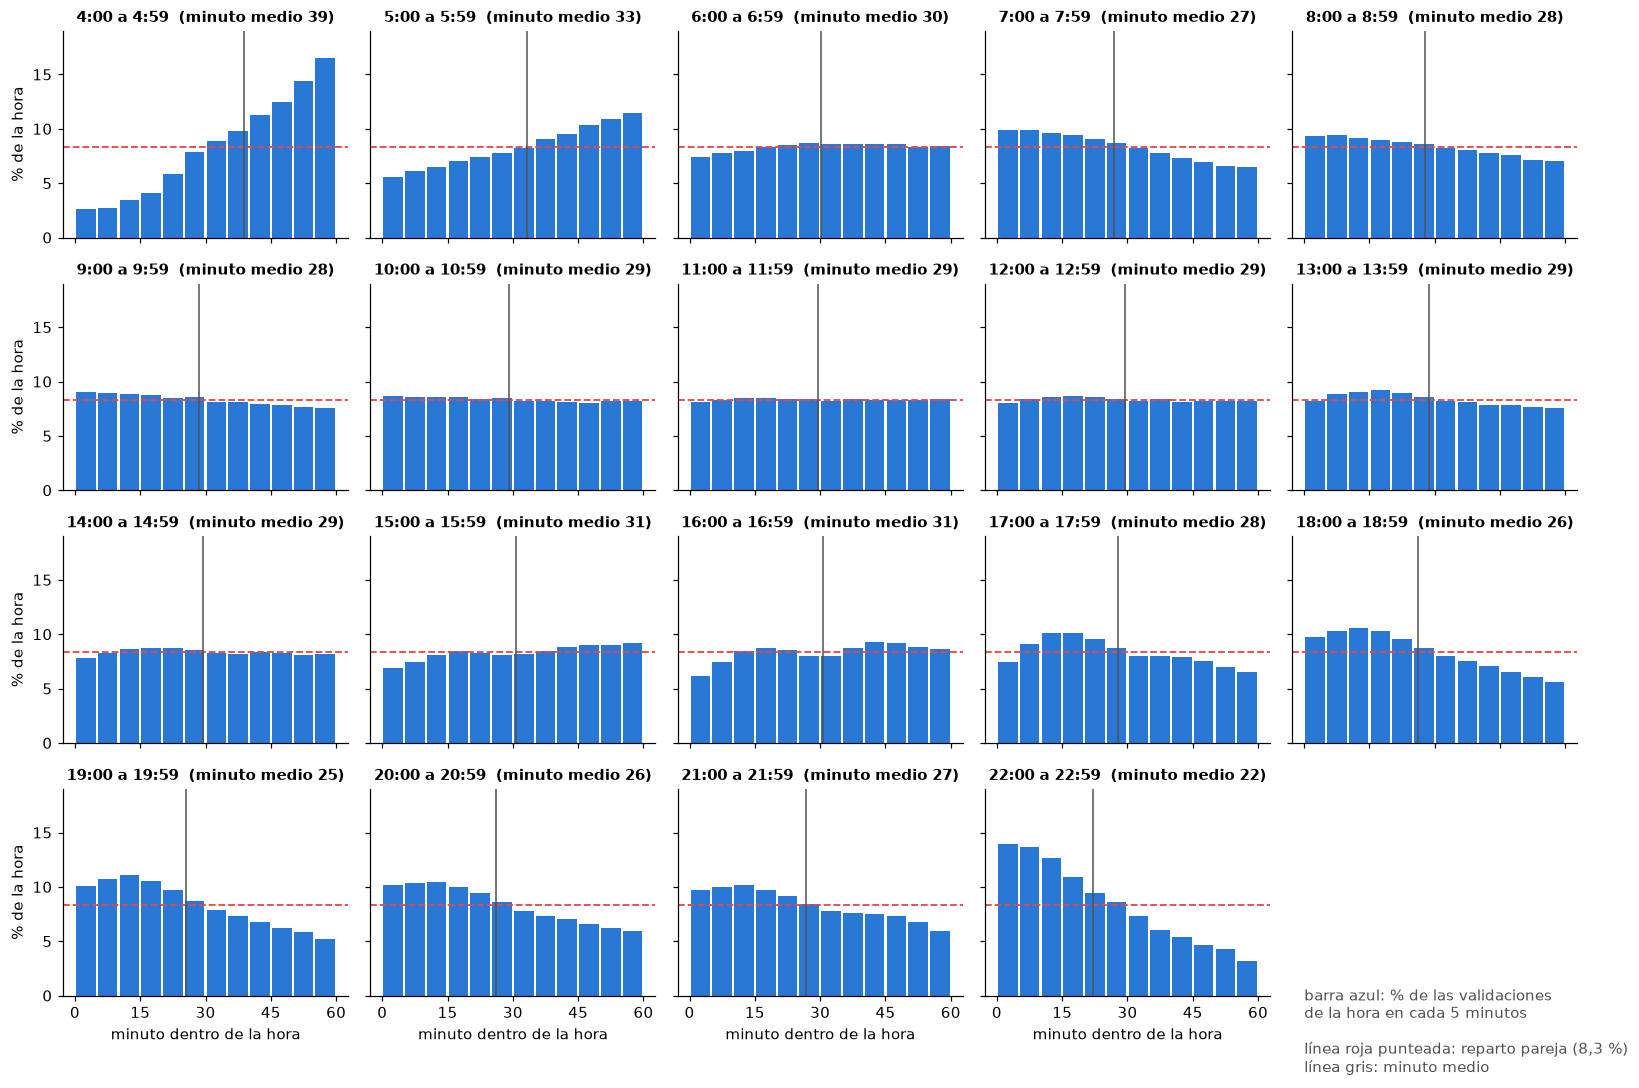

In [11]:
# QUÉ HACE: dibuja la distribución del minuto dentro de la hora para cada hora del día (de las 4 a las 22), un panel por hora.
# CÓMO: cada barra suma 5 minutos (12 barras por hora) y muestra qué % de las validaciones de esa hora cae ahí; la línea punteada es el 8,3 % que tendría cada barra si la llegada fuera pareja; la línea gris vertical marca el minuto medio.
# QUÉ MIRAR: horas con barras crecientes hacia la derecha (4, 5, 15, 16: la gente llega al final de la hora), con barras decrecientes (7, 18, 19, 20, 22: llega al principio) y horas planas pegadas a la línea punteada (9 a 14).
fig, axes = plt.subplots(4, 5, figsize=(15.5, 10), sharex=True, sharey=True)
for ax, h in zip(axes.ravel(), range(4, 23)):
    w = MH[h]; barras = w.reshape(12, 5).sum(axis=1) / w.sum() * 100
    mu_h = (mm * w / w.sum()).sum()
    ax.bar(np.arange(12) * 5 + 2.5, barras, width=4.5, color=COL['hábil'])
    ax.axhline(100 / 12, color='#e34948', lw=1.2, ls='--')
    ax.axvline(mu_h, color='#52514e', lw=1)
    ax.set_title(f"{h}:00 a {h}:59  (minuto medio {mu_h:.0f})", fontsize=9.5)
    ax.set_xticks([0, 15, 30, 45, 60]); ax.set_ylim(0, 19); ax.grid(False)
axes.ravel()[-1].axis('off')
axes.ravel()[-1].text(0.0, 0.7, 'barra azul: % de las validaciones\nde la hora en cada 5 minutos\n\nlínea roja punteada: reparto pareja (8,3 %)\nlínea gris: minuto medio', fontsize=9.5, color='#52514e', va='top')
for ax in axes[-1]: ax.set_xlabel('minuto dentro de la hora')
for ax in axes[:, 0]: ax.set_ylabel('% de la hora')
plt.tight_layout(); plt.savefig(FIGS / 'anexo_distribucion_minuto_por_hora.png', bbox_inches='tight'); plt.show()

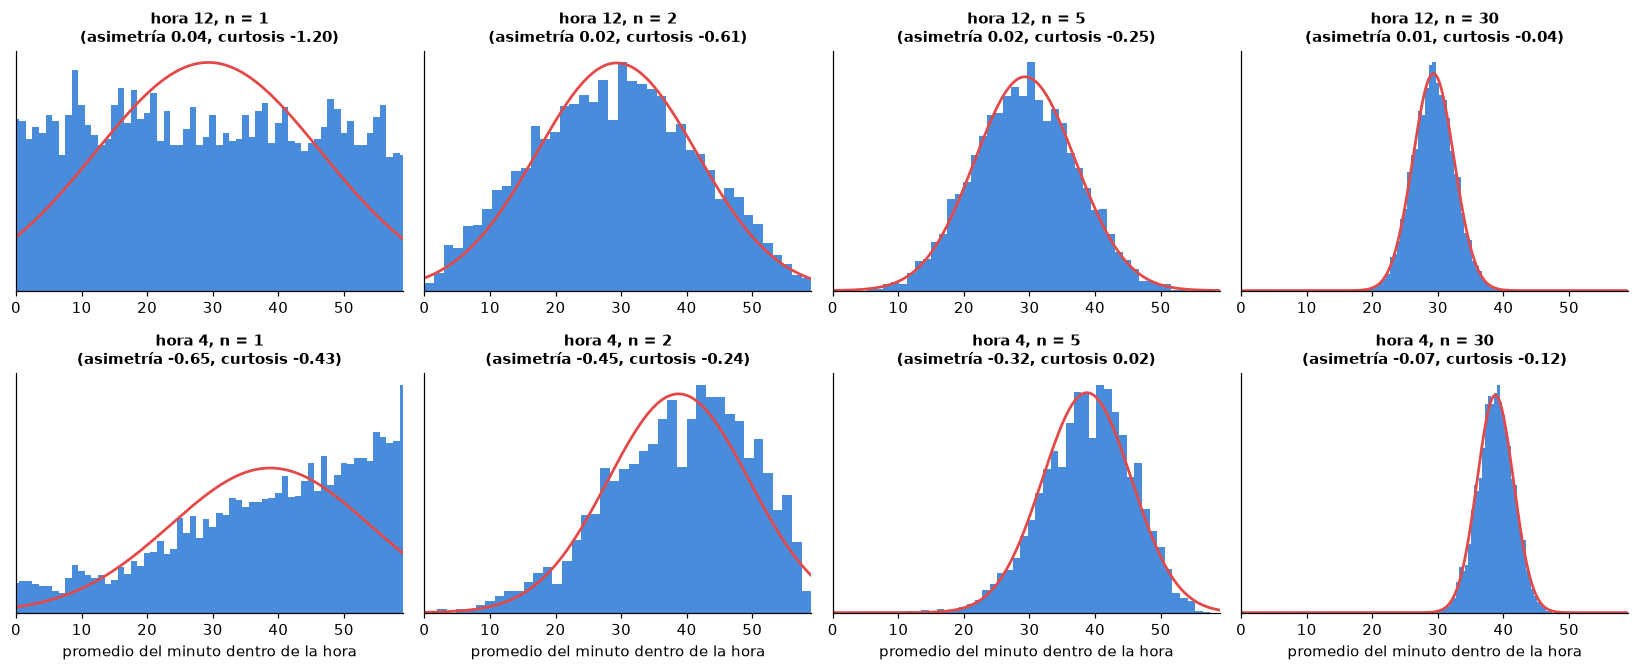

In [12]:
# QUÉ HACE: aplica el Teorema del Límite Central al minuto dentro de la hora en dos horas distintas: las 12 (llegada casi pareja, población uniforme) y las 4 (llegada creciente).
# CÓMO: para cada hora se simulan 5.000 muestras de n = 1, 2, 5 y 30 validaciones, se promedia su minuto dentro de la hora y se compara con la normal teórica N(μ, σ/√n) (línea roja).
# QUÉ MIRAR: con n = 1 la hora 12 es plana (rectángulo) y la hora 4 es una rampa; con n = 2 aparece un triángulo; con n = 5 y 30 ya es una campana ajustada a la línea roja, en las dos horas.
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
for r, h in enumerate([12, 4]):
    w = MH[h]; p = w / w.sum(); mu = (mm * p).sum(); sd = np.sqrt((p * (mm - mu) ** 2).sum())
    for c, n in enumerate([1, 2, 5, 30]):
        x = mm[rng.choice(60, size=(R, n), p=p)].mean(axis=1)
        ax = axes[r, c]; xs = np.linspace(0, 59, 300)
        ax.hist(x, bins=np.arange(-0.5, 60.5, 1) if n == 1 else 40, density=True, color=COL['hábil'], alpha=0.85)
        ax.plot(xs, stats.norm.pdf(xs, mu, sd / np.sqrt(n)), color='#e34948', lw=1.8)
        ax.set_title(f"hora {h}, n = {n}\n(asimetría {stats.skew(x):.2f}, curtosis {stats.kurtosis(x):.2f})", fontsize=9.5)
        ax.set_yticks([]); ax.grid(False); ax.set_xlim(0, 59)
        if r == 1: ax.set_xlabel('promedio del minuto dentro de la hora')
plt.tight_layout(); plt.savefig(FIGS / 'anexo_tlc_minuto_dentro_de_la_hora.png', bbox_inches='tight'); plt.show()

## 9. Conclusiones

**Medida y por qué.** La medida es el **minuto del día de la validación** y el estadístico, su **promedio muestral**. Es una variable continua, con 25,9 millones de observaciones y una distribución claramente **no normal**: en el día completo hay dos picos (media 12:09, σ = 293 min, curtosis en exceso -1,39) y, aun en la ventana de la mañana, la cima es plana (media 7:06, σ = 82 min, curtosis -0,72). Es un caso exigente para el teorema, y tiene una lectura operativa (hora media de llegada).

**Qué se verificó.**
1. **El centro y el ancho cumplen la teoría.** La desviación de los promedios simulados coincide con σ/√n: por ejemplo, con n = 30 la teórica es 53,5 min y la simulada 52,6 min; con n = 100, 29,3 contra 28,7.
2. **La forma se vuelve normal rápido.** En la población del día completo la distancia KS a la normal pasa de 0,116 (n = 1) a 0,035 (n = 2) y a 0,011 con n = 5, que ya está dentro del ruido del azar (~0,02); la curtosis pasa de -1,38 a -0,29 (n = 5) y ≈ 0 desde n = 20; el gráfico cuantil-cuantil tiene correlación 0,965 con n = 1, 0,9992 con n = 5 y 0,9999 con n = 30. Para la ventana de la mañana basta n = 3.
3. **La regla "n >= 30" es conservadora aquí.** Esta población es suave y casi simétrica; con poblaciones muy sesgadas hacen falta más datos. No se debe extrapolar el "n = 5" a cualquier variable.
4. **Los intervalos de confianza funcionan.** En la punta de la mañana de Portal Américas (587.668 validaciones, hora media real 6:40, σ = 62 min), el intervalo del 95 % con la distribución t contuvo la media verdadera en 93,7 % de las muestras con n = 5, 94,2 % con n = 10, 94,4 % con n = 30 y 94,6 % con n = 100 (95 % nominal). El ancho baja como 1/√n: ± 73 min con 5 pasajeros, ± 23 con 30 y ± 12 con 100.

**Para el proyecto.**
- El **promedio histórico de una estación-hora** (la línea base del modelo) es justamente un promedio de n = 14 días. En las 444 estaciones-hora con 1.000 o más validaciones, el semiancho mediano de su intervalo del 95 % es **± 3,7 %** del promedio (coeficiente de variación mediano 6,4 %); en Portal Américas a las 6 a. m., 14.412 validaciones ± 2,6 %. Esto da un **margen de error explícito** para la línea base y para el umbral de "alta presión": una estación-hora cuyo promedio queda a menos de ese margen del umbral es un caso dudoso.
- El 82 % de esas series diarias **no rechaza normalidad** (con 14 datos la prueba tiene poco poder; si todas fueran normales se esperaría ~95 %), así que usar promedio y distribución t es razonable, aunque no perfecto.

**Validación con la variable del modelo (sección 7).**
- **Backtest de la línea base:** con los primeros *k* días de cada una de las 444 estaciones-hora grandes se armó el intervalo del 95 % y se miró si el día siguiente caía dentro. La cobertura promedio fue **92,6 %** (algo menos que el 95 % nominal): el supuesto "los días se comportan como una normal alrededor del promedio" **es razonable pero un poco optimista**.
- **El día de la semana importa:** la cobertura es **87,5 % los lunes** y **89,8 % los viernes**, y 95-97 % de miércoles a jueves. Es la misma señal del notebook 03 (lunes ~6 % abajo, viernes ~5 % arriba): **el modelo debe incluir el día de la semana**, o la línea base sub-estima el riesgo en lunes y viernes.
- **Qué tan buena es la línea base:** el error relativo mediano al predecir el día siguiente con el promedio de los anteriores es de **3 a 7 %** (4,5 % en promedio entre días, 6 % lunes y viernes). Es el número que el modelo debe mejorar.
- **Certeza frente al umbral de 1.000 validaciones por hora:** 417 estaciones-hora lo superan con seguridad, 65 son dudosas (el intervalo contiene el umbral) y 1.667 seguramente no lo superan; es decir, el **86,5 %** de las que lo superan o están cerca son seguras. Con 500 son 90 % y con 2.000, 85 %. Las dudosas son las que conviene revisar con la operación.

**Variante: el minuto dentro de la hora (sección 8).** Propuesta de la revisión: en lugar del minuto del día, el momento *dentro de cada hora* (0 a 59).
- En las **horas de subida** la gente llega hacia el final de la hora: a las 4 el 55 % de las validaciones cae en los últimos 20 minutos (minuto medio 39) y a las 5, el 42 % (minuto medio 33).
- En las **horas de bajada** llega al principio: a las 7 el 39 % cae en los primeros 20 minutos (minuto medio 27), a las 18 el 41 % y a las 19 el 42 %.
- Entre las 9 y las 14 la llegada es **pareja** (minuto medio ~29, desviación ~17; es lo que daría un reparto uniforme).
- **Para la operación:** los conteos por hora esconden estas diferencias; en las horas de transición (4-5, 7, 18-19) el apoyo logístico debería concentrarse en la parte alta de la hora, no repartirse parejo. Es una razón para, más adelante, considerar bloques de 30 o 15 minutos en las estaciones más grandes.
- **El teorema también se verifica con esta variable:** la hora 12 (población uniforme, curtosis -1,20 con n = 1) y la hora 4 (rampa, asimetría -0,65) llegan a una campana normal con n = 30 (curtosis -0,04 y -0,12; asimetría 0,01 y -0,07).

**Limitaciones.**
- **Independencia:** el TLC supone observaciones independientes. Las validaciones de una misma tarjeta (ida y vuelta) no lo son, y los días hábiles tampoco son idénticos (lunes ~6 % abajo, viernes ~5 % arriba, notebook 03). Los intervalos de la sección 6 son una aproximación.
- **Solo 14 días** en tres semanas separadas; cinco estaciones que abren o cierran se excluyeron.
- El teorema habla del **promedio de muestras**, no de que la demanda por hora sea normal; eso se comprobó aparte (82 % de series sin rechazo).

**Dónde queda en el documento:** sección de metodología estadística del EDA; las figuras están en `docs/figs/04_*.png`.